# 🔗 Live Deployment Link: https://YOUR-APP-NAME.streamlit.app/

**Name:** Saqlain Haider &nbsp;|&nbsp; **Roll No:** SP24-BSE-109 &nbsp;|&nbsp; **Section:** FA24-BSE-A
**Course:** AIC354 – Machine Learning Fundamentals &nbsp;|&nbsp; **Assignment 2** (Fall 2026) &nbsp;|&nbsp; **Instructor:** Dr. Rao Muhammad Adeel Nawab

# Heart Disease Prediction System

## Introduction
**Definition:** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from a few clinical attributes.

**Application:** Early screening support and learning how an end-to-end ML system (data → model → deployment) is built.

**Dataset:** Heart Disease Dataset (Cleveland database) from the UCI Machine Learning Repository – https://archive.ics.uci.edu/dataset/45/heart+disease  
The original data has 14 attributes. As required by the assignment, **only 4 input attributes** are selected.

## Input and Output

### Inputs (4 attributes selected)
| Input Attribute | Original UCI attribute | Possible Values |
|---|---|---|
| **Sex** | `sex` | Male, Female |
| **ChestPain** | `cp` | Typical, Atypical, NonAnginal, Asymptomatic |
| **ExerciseAngina** | `exang` (exercise-induced angina) | Yes, No |
| **MajorVessels** | `ca` (major vessels coloured by fluoroscopy) | Zero, One, Two, Three |

### Output
| Output Attribute | Possible Values |
|---|---|
| **HeartDisease** | Yes, No |

### Examples
| Sex | ChestPain | ExerciseAngina | MajorVessels | HeartDisease |
|:-:|:-:|:-:|:-:|:-:|
| Male | Typical | No | Zero | No |
| Male | Asymptomatic | Yes | Two | Yes |
| Female | Atypical | No | Zero | No |

*Why these 4?* They are all categorical with a clear medical meaning, are easy for a user to answer, and are among the more informative attributes in the dataset.

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data (3.1 Understand, 3.2 Pre-process)
- Step 4: Feature Extraction
- Step 5: Label Encoding (5.1 Train encoders, 5.2 Encode output, 5.3 Encode input)
- Step 6: Training Phase (6.1 Split, 6.2 Input/Output split, 6.3 Train SVC, 6.4 Save model)
- Step 7: Testing Phase (7.1 – 7.5)
- Step 8: Application Phase (8.1 – 8.5)
- Step 9: Feedback Phase (9.1 – 9.3)
- Step 10: Deployment

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2: Load Sample Data

The UCI file has 14 attributes (`age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal, target`).
`heart-disease-original-14-attributes.csv` is the original data. `sample-data.csv` is the same data reduced to the **4 chosen inputs + the output**, with numeric codes replaced by readable category names (e.g. `cp=3` → `Typical`, `target` → `HeartDisease` Yes/No).

In [2]:
sample_data = pd.read_csv("sample-data.csv")
print("\n\nSample Data:")
print("============\n")
pd.set_option("display.max_rows", 20, "display.max_columns", None)
print(sample_data)



Sample Data:

        Sex     ChestPain ExerciseAngina MajorVessels HeartDisease
0      Male       Typical             No         Zero           No
1      Male    NonAnginal             No         Zero           No
2    Female      Atypical             No         Zero           No
3      Male      Atypical             No         Zero           No
4    Female  Asymptomatic            Yes         Zero           No
..      ...           ...            ...          ...          ...
293  Female  Asymptomatic            Yes         Zero          Yes
294    Male       Typical             No         Zero          Yes
295    Male  Asymptomatic             No          Two          Yes
296    Male  Asymptomatic            Yes          One          Yes
297  Female      Atypical             No          One          Yes

[298 rows x 5 columns]


## Step 3: Understand and Pre-process Sample Data
### Step 3.1: Understand Sample Data

In [3]:
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:", sample_data["Sex"].count())
print("========================================\n")

print("Missing values per column:")
print(sample_data.isnull().sum())

print("\nClass distribution of the output (HeartDisease):")
print(sample_data["HeartDisease"].value_counts())

for col in ["Sex", "ChestPain", "ExerciseAngina", "MajorVessels"]:
    print(f"\n{col}:")
    print(sample_data[col].value_counts())



Attributes in Sample Data:

Index(['Sex', 'ChestPain', 'ExerciseAngina', 'MajorVessels', 'HeartDisease'], dtype='str')


Number of Instances in Sample Data: 298

Missing values per column:
Sex               0
ChestPain         0
ExerciseAngina    0
MajorVessels      0
HeartDisease      0
dtype: int64

Class distribution of the output (HeartDisease):
HeartDisease
No     161
Yes    137
Name: count, dtype: int64

Sex:
Sex
Male      202
Female     96
Name: count, dtype: int64

ChestPain:
ChestPain
Asymptomatic    142
NonAnginal       84
Atypical         49
Typical          23
Name: count, dtype: int64

ExerciseAngina:
ExerciseAngina
No     200
Yes     98
Name: count, dtype: int64

MajorVessels:
MajorVessels
Zero     175
One       65
Two       38
Three     20
Name: count, dtype: int64


### Step 3.2: Pre-process Sample Data
Pre-processing already performed while preparing `sample-data.csv` from the original UCI data:
- Selected only the **4 input attributes** (`sex`, `cp`, `exang`, `ca`) + the output (`target`).
- Removed **1 duplicate row** and **5 rows with `ca = 4`** (an invalid value; `ca` should be 0–3). 303 → **298 instances**.
- Converted numeric codes into readable categories (the original codes are documented in the UCI dataset description).
- Output: in the original file `target = 1` means *no* heart disease (this file stores the label flipped relative to the UCI `num` column), so it was mapped to `HeartDisease = No`, and `target = 0` → `Yes`.
- No missing values in the selected columns, so no imputation is needed.

No further pre-processing needs to be performed.

## Step 4: Feature Extraction
Features are already extracted (4 categorical attributes). No feature extraction needs to be performed.

## Step 5: Label Encoding the Sample Data

### Step 5.1: Train the Label Encoder

In [4]:
sex = pd.DataFrame({"Sex": ["Male", "Female"]})
chestpain = pd.DataFrame({"ChestPain": ["Typical", "Atypical", "NonAnginal", "Asymptomatic"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
major_vessels = pd.DataFrame({"MajorVessels": ["Zero", "One", "Two", "Three"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

sex_label_encoder = LabelEncoder()
chestpain_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
major_vessels_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

sex_label_encoder.fit(np.ravel(sex))
chestpain_label_encoder.fit(np.ravel(chestpain))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
major_vessels_label_encoder.fit(np.ravel(major_vessels))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show the codes learned (LabelEncoder uses alphabetical order)
for name, enc in [("Sex", sex_label_encoder), ("ChestPain", chestpain_label_encoder),
                  ("ExerciseAngina", exercise_angina_label_encoder),
                  ("MajorVessels", major_vessels_label_encoder),
                  ("HeartDisease", heart_disease_label_encoder)]:
    print(name, "->", dict(zip(enc.classes_, [int(v) for v in enc.transform(enc.classes_)])))

Sex -> {'Female': 0, 'Male': 1}
ChestPain -> {'Asymptomatic': 0, 'Atypical': 1, 'NonAnginal': 2, 'Typical': 3}
ExerciseAngina -> {'No': 0, 'Yes': 1}
MajorVessels -> {'One': 0, 'Three': 1, 'Two': 2, 'Zero': 3}
HeartDisease -> {'No': 0, 'Yes': 1}


### Step 5.2: Label Encode the Output

In [5]:
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data["encoded_heartdisease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_heartdisease"]].head(10))

sample_data_encoded_output[["Sex", "ChestPain", "ExerciseAngina", "MajorVessels", "HeartDisease"]] = \
    sample_data[["Sex", "ChestPain", "ExerciseAngina", "MajorVessels", "encoded_heartdisease"]]

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heartdisease
0           No                     0
1           No                     0
2           No                     0
3           No                     0
4           No                     0
5           No                     0
6           No                     0
7           No                     0
8           No                     0
9           No                     0

Saved: sample-data-encoded-output.csv


### Step 5.3: Label Encode the Input

In [6]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded_output["encoded_sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded_output["encoded_chestpain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exercise_angina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded_output["encoded_major_vessels"] = major_vessels_label_encoder.transform(sample_data_encoded_output["MajorVessels"])

sample_data_encoded[["Sex", "ChestPain", "ExerciseAngina", "MajorVessels", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_sex", "encoded_chestpain", "encoded_exercise_angina", "encoded_major_vessels", "HeartDisease"]]

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded.head(10))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding:

   Sex  ChestPain  ExerciseAngina  MajorVessels  HeartDisease
0    1          3               0             3             0
1    1          2               0             3             0
2    0          1               0             3             0
3    1          1               0             3             0
4    0          0               1             3             0
5    1          0               0             3             0
6    0          1               0             3             0
7    1          1               0             3             0
8    1          2               0             3             0
9    1          2               0             3             0


## Step 6: Execute the Training Phase
### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
# 80% training / 20% testing. The data is shuffled (random_state=0 keeps it reproducible)
# and stratified so both splits keep the same Yes/No proportion.
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"]
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (238, 5)
Testing Data shape: (60, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (238, 4)
Output labels (train) shape: (238,)


### Step 6.3: Train the Support Vector Classifier

In [9]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [10]:
pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


## Step 7: Execute the Testing Phase
### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


### Step 7.2: Load the Saved Model

In [12]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model
#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [13]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by heart_svc_trained_model:")
print("================================================\n")
print(model_predictions)



Predictions Returned by heart_svc_trained_model:

     Sex  ChestPain  ExerciseAngina  MajorVessels  HeartDisease  Predictions
192    1          2               0             3             1            0
162    1          0               1             2             1            1
201    1          0               1             0             1            1
215    1          0               1             2             1            1
279    1          0               1             0             1            1
..   ...        ...             ...           ...           ...          ...
199    1          2               1             3             1            0
114    0          2               0             3             0            0
103    1          2               0             3             0            0
29     1          2               0             3             0            0
153    0          2               0             3             0            0

[60 rows x 6 columns]


### Step 7.4: Calculate the Accuracy Score

In [14]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.82


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.77      0.94      0.85        32
   Heart Disease (1)       0.90      0.68      0.78        28

            accuracy                           0.82        60
           macro avg       0.84      0.81      0.81        60
        weighted avg       0.83      0.82      0.81        60


Confusion Matrix:

             Predicted: No  Predicted: Yes
Actual: No              30               2
Actual: Yes              9              19


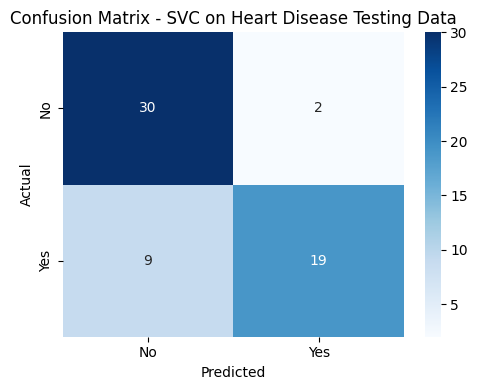

In [15]:
# Encoded: 0 = No heart disease, 1 = Yes heart disease (alphabetical order of the encoder)
class_names = list(heart_disease_label_encoder.classes_)   # ['No', 'Yes']

print("\nClassification Report:")
print("=======================\n")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Heart Disease (0)", "Heart Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("\nConfusion Matrix:")
print("==================\n")
print(pd.DataFrame(conf_matrix,
                   index=["Actual: No", "Actual: Yes"],
                   columns=["Predicted: No", "Predicted: Yes"]))

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

## Step 8: Execute the Application Phase
### Step 8.1: Take Input from User

In [16]:
# Demo patient (edit these values, or replace with input() calls to type them in):
#   sex_input = input("Sex (Male, Female): ").strip()
#   chestpain_input = input("ChestPain (Typical, Atypical, NonAnginal, Asymptomatic): ").strip()
#   exercise_angina_input = input("ExerciseAngina (Yes, No): ").strip()
#   major_vessels_input = input("MajorVessels (Zero, One, Two, Three): ").strip()
sex_input = "Male"
chestpain_input = "Asymptomatic"
exercise_angina_input = "Yes"
major_vessels_input = "Two"

print(f"Sex: {sex_input}, ChestPain: {chestpain_input}, ExerciseAngina: {exercise_angina_input}, MajorVessels: {major_vessels_input}")

Sex: Male, ChestPain: Asymptomatic, ExerciseAngina: Yes, MajorVessels: Two


### Step 8.2: Convert User Input into Feature Vector (same as Sample Data)

In [17]:
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chestpain_input],
    "ExerciseAngina": [exercise_angina_input],
    "MajorVessels": [major_vessels_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:



    Sex     ChestPain ExerciseAngina MajorVessels
0  Male  Asymptomatic            Yes          Two


### Step 8.3: Label Encoding of Feature Vector

In [18]:
unseen_data_features = user_input.copy()
unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["MajorVessels"] = major_vessels_label_encoder.transform(user_input["MajorVessels"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   Sex  ChestPain  ExerciseAngina  MajorVessels
0    1          0               1             2


### Step 8.4: Load the Saved Model

In [19]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction
#### Step 8.5.1: Apply Model on the Encoded Feature Vector and return Prediction to the User

In [20]:
predicted_heart_disease = model.predict(unseen_data_features)

# 1 = "Yes" (heart disease), 0 = "No" (alphabetical encoding)
if predicted_heart_disease[0] == 1:
    prediction = "HEART DISEASE DETECTED"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("     ** Prediction **     ", [prediction])
print(pretty_table)

+----------------------------+
|      ** Prediction **      |
+----------------------------+
|   HEART DISEASE DETECTED   |
+----------------------------+


## Step 9: Execute the Feedback Phase
### Step 9.1: Collect Feedback from Users and Domain Experts

In [21]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Student Tester", "Student Tester"],
    "Case": [
        "Male, Asymptomatic chest pain, exercise angina Yes, 2 vessels -> predicted HEART DISEASE",
        "Female, Atypical chest pain, no exercise angina, 0 vessels -> predicted NO HEART DISEASE",
        "Male, Typical chest pain, no angina, 0 vessels -> predicted NO HEART DISEASE (borderline)",
    ],
    "Feedback": [
        "Plausible: blocked vessels and exercise-induced angina are known risk indicators.",
        "Plausible: low-risk profile on all four inputs.",
        "Uncertain - only 4 inputs are used, so age, cholesterol and blood pressure are ignored; the model should not be used for real diagnosis.",
    ],
})
print(example_feedback.to_string(index=False))

                  Reviewer                                                                                      Case                                                                                                                                 Feedback
Domain Expert (Cardiology)  Male, Asymptomatic chest pain, exercise angina Yes, 2 vessels -> predicted HEART DISEASE                                                        Plausible: blocked vessels and exercise-induced angina are known risk indicators.
            Student Tester  Female, Atypical chest pain, no exercise angina, 0 vessels -> predicted NO HEART DISEASE                                                                                          Plausible: low-risk profile on all four inputs.
            Student Tester Male, Typical chest pain, no angina, 0 vessels -> predicted NO HEART DISEASE (borderline) Uncertain - only 4 inputs are used, so age, cholesterol and blood pressure are ignored; the model should not be used for 

### Step 9.2: Make a List of Potential Improvements

In [22]:
improvements = [
    "Use more attributes (age, cholesterol, resting blood pressure, max heart rate, oldpeak) to capture risk factors the 4-input model ignores",
    "Use a larger dataset (combine Cleveland with Hungarian, Switzerland and Long Beach VA) so the model generalises better",
    "Use k-fold cross validation instead of a single 80/20 split for a more reliable accuracy estimate",
    "Compare other models (Logistic Regression, Decision Tree, Random Forest) and tune SVC parameters (C, kernel, gamma)",
    "Add recall-focused evaluation, since missing a real heart-disease case is costlier than a false alarm",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (age, cholesterol, resting blood pressure, max heart rate, oldpeak) to capture risk factors the 4-input model ignores


2. Use a larger dataset (combine Cleveland with Hungarian, Switzerland and Long Beach VA) so the model generalises better
3. Use k-fold cross validation instead of a single 80/20 split for a more reliable accuracy estimate
4. Compare other models (Logistic Regression, Decision Tree, Random Forest) and tune SVC parameters (C, kernel, gamma)
5. Add recall-focused evaluation, since missing a real heart-disease case is costlier than a false alarm


### Step 9.3: Improve the Model Based on Feedback

In [23]:
print("Next version: retrain with additional attributes on a larger dataset, validate with k-fold cross validation, and replace heart_svc_trained_model.pkl only if the metrics improve.")

Next version: retrain with additional attributes on a larger dataset, validate with k-fold cross validation, and replace heart_svc_trained_model.pkl only if the metrics improve.


## Step 10: Deploy the Model on the Cloud
The trained model is deployed as a Streamlit web app on **Streamlit Community Cloud** (same approach as the instructor's Titanic demo).

**Files used for deployment** (in this folder):
- `app.py` – the web app (loads `heart_svc_trained_model.pkl`, re-creates the same LabelEncoders, predicts)
- `heart_svc_trained_model.pkl` – the trained model produced in Step 6.4
- `requirements.txt` and `runtime.txt` – package versions and Python version

**Steps:**
1. Create a public GitHub repo and upload `app.py`, `heart_svc_trained_model.pkl`, `requirements.txt`, `runtime.txt`.
2. Go to https://share.streamlit.io → sign in with GitHub → **New app** → pick the repo, branch `main`, main file `app.py` → **Deploy**.
3. Copy the generated `https://....streamlit.app/` URL and paste it at the **very top** of this notebook.

## Conclusion
A complete end-to-end ML system was built for heart disease prediction using only **4 input attributes** (Sex, ChestPain, ExerciseAngina, MajorVessels) from the UCI Heart Disease (Cleveland) dataset. After label encoding, a Support Vector Classifier was trained (Step 6), tested with accuracy, precision, recall, F1 and a confusion matrix (Step 7), used on new input (Step 8), reviewed through feedback (Step 9) and deployed to the cloud (Step 10). The model is for learning purposes only and is not a medical diagnostic tool.